# 第 11 章 配套验证代码：只算变化的部分（差分推理、截断缓冲与图上多跳扩散）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch11_delta_and_sparse_updates.ipynb)

本 Notebook 仅使用 `numpy` 与 `matplotlib`，逐项验证第 11 章的全部公式与手算例子：
1. 线性层的增量穿透 $f(\mathbf{x}_t) = f(\mathbf{x}_{t-1}) + W\Delta_t$ 与 ReLU 非线性反例（DeltaCNN 式 1–3）
2. **例 11.1**：6 帧缓慢爬坡信号上，朴素帧间截断（漂移崩溃）、DeltaCNN 截断误差缓冲（零漂移、误差严格 $< \Theta$）与 Sigma-Delta Herding（等价取整网络，误差 $\le \Theta/2$）逐帧对照
3. 多层线性+ReLU 网络逐层截断误差递推上界验证（推导，非论文原文）
4. **例 11.2**：5 节点链状图 $0-1-2-3-4$ 上的 $k$ 跳扩散（$\hat{A}^k$ 非零区域）与逐层阈值截断压制扩散的定量实验
5. 练习题代码探索区（修改阈值 $\Theta$ 与扩散层数 $k$ 观察计算量—误差权衡）

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

def setup_plot_font():
    """配置中文字体；若当前环境缺少中文字体，则自动回退英文标签避免方框。"""
    candidates = [
        'SimHei', 'Microsoft YaHei', 'PingFang SC',
        'Noto Sans CJK SC', 'WenQuanYi Micro Hei', 'Source Han Sans SC'
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in candidates:
        if name in available:
            plt.rcParams['font.sans-serif'] = [name, 'DejaVu Sans']
            plt.rcParams['axes.unicode_minus'] = False
            return True
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
    plt.rcParams['axes.unicode_minus'] = False
    return False

USE_ZH = setup_plot_font()
np.set_printoptions(precision=4, suppress=True)
print(f"Font setup done. USE_ZH = {USE_ZH}")


Font setup done. USE_ZH = True


## 1. 线性层的增量穿透与 ReLU 非线性反例（DeltaCNN 式 1–3）

In [2]:
# 1.1 线性层增量穿透: W(x_{t-1} + delta) + b = (W x_{t-1} + b) + W delta
W = np.array([[1.5, -0.5],
              [0.2,  2.0]], dtype=float)
b = np.array([0.3, -0.4], dtype=float)
x_prev = np.array([1.0, -0.5], dtype=float)
delta = np.array([0.2,  0.1], dtype=float)
x_curr = x_prev + delta

y_prev = W @ x_prev + b
y_curr_dense = W @ x_curr + b
# 注意：增量更新时不再重复加偏置 b（DeltaCNN Sec. 3.1, p. 4）
y_curr_delta = y_prev + W @ delta

print("y_curr (dense):", y_curr_dense)
print("y_curr (delta):", y_curr_delta)
assert np.allclose(y_curr_dense, y_curr_delta, atol=1e-12)

# 1.2 非线性 ReLU 反例（DeltaCNN Sec. 3.1, p. 4 原文数字）
relu = lambda z: np.maximum(z, 0.0)
z_prev, dz = -1.0, 2.0
lhs = relu(z_prev) + relu(dz)     # 0 + 2 = 2
rhs = relu(z_prev + dz)           # ReLU(1) = 1
delta_y_exact = relu(z_prev + dz) - relu(z_prev)  # DeltaCNN Eq. (3)
print(f"ReLU(-1) + ReLU(2) = {lhs:.1f} != ReLU(-1 + 2) = {rhs:.1f}")
print(f"保存状态后的精确差分输出 delta_y = ReLU(1) - ReLU(-1) = {delta_y_exact:.1f}")
assert lhs == 2.0 and rhs == 1.0 and lhs != rhs
assert np.isclose(relu(z_prev) + delta_y_exact, rhs)
print("[PASS] 线性增量穿透与 ReLU 非线性反例验证通过！")


y_curr (dense): [ 2.3  -0.96]
y_curr (delta): [ 2.3  -0.96]
ReLU(-1) + ReLU(2) = 2.0 != ReLU(-1 + 2) = 1.0
保存状态后的精确差分输出 delta_y = ReLU(1) - ReLU(-1) = 1.0
[PASS] 线性增量穿透与 ReLU 非线性反例验证通过！


## 2. 例 11.1：缓慢爬坡信号——朴素截断 vs 截断误差缓冲（DeltaCNN）vs Sigma-Delta Herding

In [3]:
# 6 帧缓慢爬坡信号：每帧只涨 0.08，截断阈值 Theta = 0.20
x_seq = np.array([0.00, 0.08, 0.16, 0.24, 0.32, 0.40], dtype=float)
theta = 0.20

# 方法 A：朴素帧间截断（不保存未发送残差，每次只看 |x_t - x_{t-1}| < theta）
naive_hat = np.zeros_like(x_seq)
naive_sent = np.zeros_like(x_seq)
for t in range(1, len(x_seq)):
    dx = x_seq[t] - x_seq[t - 1]
    if abs(dx) >= theta - 1e-12:
        naive_sent[t] = dx
        naive_hat[t] = naive_hat[t - 1] + dx
    else:
        naive_sent[t] = 0.0
        naive_hat[t] = naive_hat[t - 1]

# 方法 B：带截断误差缓冲（DeltaCNN Eq. 5-6 / Delta Network / EvNets）
# 恒等激活 f(x)=x 情形：x_A 为上次发出的累积状态，x_T 为累计截断残差
buf_hat = np.zeros_like(x_seq)
buf_sent = np.zeros_like(x_seq)
buf_xT = np.zeros_like(x_seq)
xA = 0.0
xT = 0.0
for t in range(1, len(x_seq)):
    dx = x_seq[t] - x_seq[t - 1]
    cand = xT + dx
    if abs(cand) >= theta - 1e-12:
        buf_sent[t] = cand
        xA = xA + cand
        xT = 0.0
    else:
        buf_sent[t] = 0.0
        xT = cand
    buf_hat[t] = xA
    buf_xT[t] = xT

# 方法 C：Sigma-Delta Herding（O'Connor & Welling ICLR 2017 Alg. 3 & Eq. 2, 步长 1/k = theta = 0.20）
k_scale = 1.0 / theta  # k = 5.0
sd_hat = np.zeros_like(x_seq)
sd_spikes = np.zeros_like(x_seq)
phi = 0.0
acc = 0.0
for t in range(1, len(x_seq)):
    dx = x_seq[t] - x_seq[t - 1]
    phi = phi + k_scale * dx
    s = np.round(phi)          # 整数脉冲（带符号）
    phi = phi - s
    acc = acc + s / k_scale    # 积分器 Sigma_T
    sd_spikes[t] = s
    sd_hat[t] = acc

# 验证 Sigma-Delta 等价于取整网络: Sigma_T(herd(Delta_T(x))) == round(k*x)/k
round_net = np.round(k_scale * x_seq) / k_scale

print("t |  x_t | Naive_hat (err)  | Buf_sent  Buf_xT  Buf_hat (err)   | SD_s  SD_hat (err)")
print("-" * 88)
for t in range(len(x_seq)):
    print(f"{t} | {x_seq[t]:.2f} |  {naive_hat[t]:.2f}  ({naive_hat[t]-x_seq[t]:+.2f})   |"
          f"   {buf_sent[t]:.2f}     {buf_xT[t]:.2f}    {buf_hat[t]:.2f}  ({buf_hat[t]-x_seq[t]:+.2f})  |"
          f"  {int(sd_spikes[t]):+d}    {sd_hat[t]:.2f}  ({sd_hat[t]-x_seq[t]:+.2f})")

# 严格断言手算结果
assert np.allclose(naive_hat, [0.0, 0.0, 0.0, 0.0, 0.0, 0.0])
# 检查缓冲方法真实值：t=3 发 0.24（xA=0.24, xT=0），t=4 xT=0.08，t=5 xT=0.16 < 0.20（未发！）
assert np.allclose(buf_sent, [0.0, 0.0, 0.0, 0.24, 0.0, 0.0], atol=1e-12)
assert np.allclose(buf_hat,  [0.0, 0.0, 0.0, 0.24, 0.24, 0.24], atol=1e-12)
assert np.all(np.abs(buf_hat - x_seq) < theta)
assert np.allclose(sd_hat, round_net, atol=1e-12)
assert np.all(np.abs(sd_hat - x_seq) <= theta / 2.0 + 1e-12)
print("[PASS] 例 11.1 全部手算数值与误差界验证通过！")


t |  x_t | Naive_hat (err)  | Buf_sent  Buf_xT  Buf_hat (err)   | SD_s  SD_hat (err)
----------------------------------------------------------------------------------------
0 | 0.00 |  0.00  (+0.00)   |   0.00     0.00    0.00  (+0.00)  |  +0    0.00  (+0.00)
1 | 0.08 |  0.00  (-0.08)   |   0.00     0.08    0.00  (-0.08)  |  +0    0.00  (-0.08)
2 | 0.16 |  0.00  (-0.16)   |   0.00     0.16    0.00  (-0.16)  |  +1    0.20  (+0.04)
3 | 0.24 |  0.00  (-0.24)   |   0.24     0.00    0.24  (+0.00)  |  +0    0.20  (-0.04)
4 | 0.32 |  0.00  (-0.32)   |   0.00     0.08    0.24  (-0.08)  |  +1    0.40  (+0.08)
5 | 0.40 |  0.00  (-0.40)   |   0.00     0.16    0.24  (-0.16)  |  +0    0.40  (+0.00)
[PASS] 例 11.1 全部手算数值与误差界验证通过！


## 3. 长期爬坡（30 帧）与多层截断误差递推上界验证（推导，非论文原文）

30 帧缓慢爬坡：朴素截断最大误差 = 2.32（无限漂移）
              缓冲截断最大误差 = 0.16 < 0.20（仅触发 9/29 次）
              Sigma-Delta 最大误差 = 0.08 <= 0.10（仅触发 12/29 次）
两层网络经验最大无穷范数误差 = 0.1207 <= 理论上界 0.1830


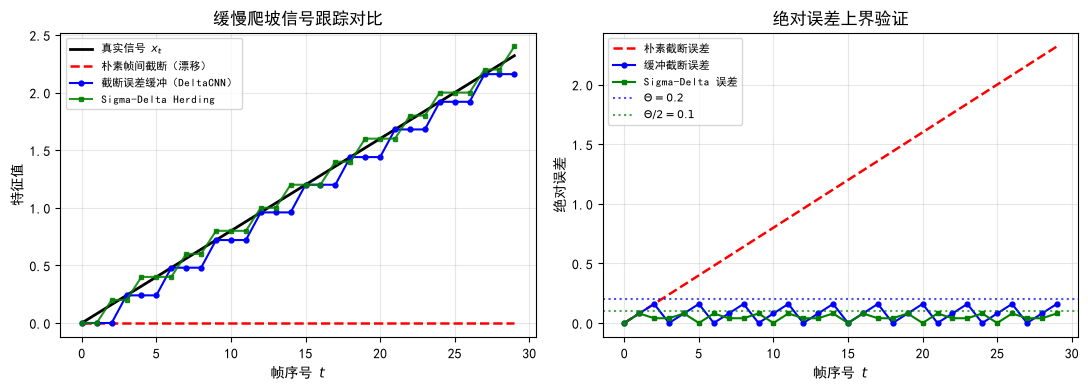

[PASS] 误差界与无漂移跟踪验证通过！


In [4]:
# 3.1 30 帧缓慢爬坡直观对比（画图）
T_frames = 30
x_long = 0.08 * np.arange(T_frames)
theta = 0.20

naive_l = np.zeros(T_frames)
buf_l = np.zeros(T_frames)
sd_l = np.zeros(T_frames)
xA, xT = 0.0, 0.0
phi, acc = 0.0, 0.0
buf_tx, sd_tx = 0, 0
for t in range(1, T_frames):
    dx = x_long[t] - x_long[t - 1]
    # naive
    naive_l[t] = naive_l[t - 1] + (dx if abs(dx) >= theta else 0.0)
    # residual buffer
    if abs(xT + dx) >= theta - 1e-12:
        xA += xT + dx
        xT = 0.0
        buf_tx += 1
    else:
        xT += dx
    buf_l[t] = xA
    # sigma-delta
    phi += dx / theta
    s = np.round(phi)
    phi -= s
    acc += s * theta
    if s != 0:
        sd_tx += 1
    sd_l[t] = acc

assert np.max(np.abs(naive_l - x_long)) > 2.0
assert np.max(np.abs(buf_l - x_long)) < theta + 1e-12
assert np.max(np.abs(sd_l - x_long)) <= theta / 2.0 + 1e-12
print(f"30 帧缓慢爬坡：朴素截断最大误差 = {np.max(np.abs(naive_l-x_long)):.2f}（无限漂移）")
print(f"              缓冲截断最大误差 = {np.max(np.abs(buf_l-x_long)):.2f} < {theta:.2f}（仅触发 {buf_tx}/{T_frames-1} 次）")
print(f"              Sigma-Delta 最大误差 = {np.max(np.abs(sd_l-x_long)):.2f} <= {theta/2:.2f}（仅触发 {sd_tx}/{T_frames-1} 次）")

# 3.2 验证两层网络逐层截断误差递推上界: e_2 <= ||W2||_inf * e_1 + eps_2
rng = np.random.default_rng(42)
W1 = rng.uniform(-0.8, 0.8, size=(6, 4))
W2 = rng.uniform(-0.8, 0.8, size=(5, 6))
eps1, eps2 = 0.05, 0.04
norm_W2_inf = np.max(np.sum(np.abs(W2), axis=1))
theory_bound = norm_W2_inf * eps1 + eps2

max_emp_err = 0.0
for _ in range(500):
    x = rng.normal(size=4)
    y1_true = np.maximum(W1 @ x, 0.0)
    y2_true = np.maximum(W2 @ y1_true, 0.0)
    # 模拟各层截断误差 <= eps_l
    y1_hat = y1_true + rng.uniform(-eps1, eps1, size=6)
    y2_hat = np.maximum(W2 @ y1_hat, 0.0) + rng.uniform(-eps2, eps2, size=5)
    max_emp_err = max(max_emp_err, np.max(np.abs(y2_hat - y2_true)))

print(f"两层网络经验最大无穷范数误差 = {max_emp_err:.4f} <= 理论上界 {theory_bound:.4f}")
assert max_emp_err <= theory_bound + 1e-12

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(x_long, 'k-', lw=2, label='真实信号 $x_t$' if USE_ZH else 'True $x_t$')
ax.plot(naive_l, 'r--', lw=1.8, label='朴素帧间截断（漂移）' if USE_ZH else 'Naive diff (drifts)')
ax.plot(buf_l, 'b-o', ms=3.5, label='截断误差缓冲（DeltaCNN）' if USE_ZH else 'Residual buffer (DeltaCNN)')
ax.plot(sd_l, 'g-s', ms=3, alpha=0.85, label='Sigma-Delta Herding' if USE_ZH else 'Sigma-Delta Herding')
ax.set_xlabel('帧序号 $t$' if USE_ZH else 'Frame $t$')
ax.set_ylabel('特征值' if USE_ZH else 'Value')
ax.set_title('缓慢爬坡信号跟踪对比' if USE_ZH else 'Slow Ramp Tracking')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(np.abs(naive_l - x_long), 'r--', lw=1.8, label='朴素截断误差' if USE_ZH else 'Naive |err|')
ax.plot(np.abs(buf_l - x_long), 'b-o', ms=3.5, label='缓冲截断误差' if USE_ZH else 'Buffer |err|')
ax.plot(np.abs(sd_l - x_long), 'g-s', ms=3, label='Sigma-Delta 误差' if USE_ZH else 'Sigma-Delta |err|')
ax.axhline(theta, color='b', ls=':', alpha=0.7, label=rf'$\Theta={theta}$')
ax.axhline(theta/2, color='g', ls=':', alpha=0.7, label=rf'$\Theta/2={theta/2}$')
ax.set_xlabel('帧序号 $t$' if USE_ZH else 'Frame $t$')
ax.set_ylabel('绝对误差' if USE_ZH else 'Absolute Error')
ax.set_title('绝对误差上界验证' if USE_ZH else 'Error Bound Verification')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("[PASS] 误差界与无漂移跟踪验证通过！")


## 4. 例 11.2：5 节点链状图上的 $k$ 跳扩散与阈值截断抑制

加自环度数: [2. 3. 3. 3. 2.]
对称归一化邻接矩阵 A_hat:
[[0.5    0.4082 0.     0.     0.    ]
 [0.4082 0.3333 0.3333 0.     0.    ]
 [0.     0.3333 0.3333 0.3333 0.    ]
 [0.     0.     0.3333 0.3333 0.4082]
 [0.     0.     0.     0.4082 0.5   ]]

左端节点 0 变化时，A_hat^k e_0 各层非零分布：
  k=0: vec=[1. 0. 0. 0. 0.]  受影响节点=[0] (1/5 = 20%)
  k=1: vec=[0.5    0.4082 0.     0.     0.    ]  受影响节点=[0, 1] (2/5 = 40%)
  k=2: vec=[0.4167 0.3402 0.1361 0.     0.    ]  受影响节点=[0, 1, 2] (3/5 = 60%)
  k=3: vec=[0.3472 0.3289 0.1588 0.0454 0.    ]  受影响节点=[0, 1, 2, 3] (4/5 = 80%)
  k=4: vec=[0.3079 0.3043 0.1777 0.068  0.0185]  受影响节点=[0, 1, 2, 3, 4] (5/5 = 100%)

中心节点 2 变化时，只需 k=2 跳就波及全图 100%：
  k=0: vec=[0. 0. 1. 0. 0.]  受影响节点=[2] (1/5 = 20%)
  k=1: vec=[0.     0.3333 0.3333 0.3333 0.    ]  受影响节点=[1, 2, 3] (3/5 = 60%)
  k=2: vec=[0.1361 0.2222 0.3333 0.2222 0.1361]  受影响节点=[0, 1, 2, 3, 4] (5/5 = 100%)

左端节点 0 变化 + 逐层截断阈值 eps=0.15：
  k=1: 截断前=[0.5    0.4082 0.     0.     0.    ] -> 截断后=[0.5    0.4082 0.     0.     0.    ], 活跃节

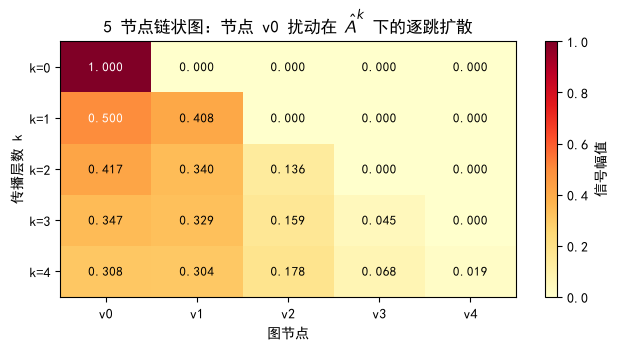

[PASS] 例 11.2 链状图多跳扩散与阈值截断验证通过！


In [5]:
# 5 节点链状图 0 - 1 - 2 - 3 - 4（加自环）
N = 5
A = np.zeros((N, N), dtype=float)
for i in range(N - 1):
    A[i, i + 1] = 1.0
    A[i + 1, i] = 1.0
A_tilde = A + np.eye(N)
deg = np.sum(A_tilde, axis=1)           # [2, 3, 3, 3, 2]
D_inv_sqrt = np.diag(1.0 / np.sqrt(deg))
A_hat = D_inv_sqrt @ A_tilde @ D_inv_sqrt

print("加自环度数:", deg)
print("对称归一化邻接矩阵 A_hat:")
print(A_hat)

# 情形 1：左端节点 0 发生变化 delta^(0) = [1, 0, 0, 0, 0]^T
e0 = np.array([1.0, 0.0, 0.0, 0.0, 0.0])
powers_e0 = [e0]
cur = e0.copy()
for k in range(1, 5):
    cur = A_hat @ cur
    powers_e0.append(cur.copy())

print("\n左端节点 0 变化时，A_hat^k e_0 各层非零分布：")
for k, vec in enumerate(powers_e0):
    nz = np.where(vec > 1e-12)[0].tolist()
    print(f"  k={k}: vec={np.round(vec, 4)}  受影响节点={nz} ({len(nz)}/{N} = {len(nz)/N*100:.0f}%)")
    assert nz == list(range(k + 1))

# 情形 2：中心节点 2 发生变化 delta^(0) = [0, 0, 1, 0, 0]^T
e2 = np.array([0.0, 0.0, 1.0, 0.0, 0.0])
powers_e2 = [e2]
cur = e2.copy()
for k in range(1, 3):
    cur = A_hat @ cur
    powers_e2.append(cur.copy())
print("\n中心节点 2 变化时，只需 k=2 跳就波及全图 100%：")
for k, vec in enumerate(powers_e2):
    nz = np.where(vec > 1e-12)[0].tolist()
    print(f"  k={k}: vec={np.round(vec, 4)}  受影响节点={nz} ({len(nz)}/{N} = {len(nz)/N*100:.0f}%)")
assert len(np.where(powers_e2[1] > 1e-12)[0]) == 3
assert len(np.where(powers_e2[2] > 1e-12)[0]) == 5

# 情形 3：加入逐层截断阈值 eps = 0.15，看受影响节点是否被压制
eps_graph = 0.15
cur_trunc = e0.copy()
print(f"\n左端节点 0 变化 + 逐层截断阈值 eps={eps_graph}：")
trunc_counts = [1]
for k in range(1, 5):
    nxt = A_hat @ cur_trunc
    nxt_trunc = np.where(np.abs(nxt) >= eps_graph, nxt, 0.0)
    nz = np.where(np.abs(nxt_trunc) > 1e-12)[0].tolist()
    trunc_counts.append(len(nz))
    print(f"  k={k}: 截断前={np.round(nxt, 4)} -> 截断后={np.round(nxt_trunc, 4)}, 活跃节点={nz}")
    cur_trunc = nxt_trunc

assert trunc_counts[-1] < N  # 阈值成功阻止了波及全图
# 画扩散热力图
mat = np.array(powers_e0)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
im = ax.imshow(mat, cmap='YlOrRd', aspect='auto')
for k in range(5):
    for j in range(5):
        ax.text(j, k, f"{mat[k, j]:.3f}", ha='center', va='center',
                color='white' if mat[k, j] > 0.45 else 'black', fontsize=9)
ax.set_xticks(range(5))
ax.set_xticklabels([f"v{j}" for j in range(5)])
ax.set_yticks(range(5))
ax.set_yticklabels([f"k={k}" for k in range(5)])
ax.set_xlabel("图节点" if USE_ZH else "Graph Node")
ax.set_ylabel("传播层数 k" if USE_ZH else "Layer k")
ax.set_title(r"5 节点链状图：节点 v0 扰动在 $\hat{A}^k$ 下的逐跳扩散" if USE_ZH else "5-Node Chain Graph: k-Hop Diffusion of Perturbation at v0")
plt.colorbar(im, ax=ax, label="信号幅值" if USE_ZH else "Magnitude")
plt.tight_layout()
plt.show()
print("[PASS] 例 11.2 链状图多跳扩散与阈值截断验证通过！")


## 5. 练习探索区：修改阈值与脉冲缓冲观察权衡

In [6]:
# 练习探索：扫描截断阈值 eps，观察 5 节点链状图 4 层传播中的总活跃节点数与末层误差
eps_grid = [0.0, 0.05, 0.10, 0.15, 0.25, 0.40]
exact_k4 = powers_e0[4]
print("eps   | 4层总更新节点次(满分20) | 第4层最大误差")
print("-" * 46)
for eps in eps_grid:
    cur = e0.copy()
    active_total = 0
    for _ in range(4):
        cur = A_hat @ cur
        cur = np.where(np.abs(cur) >= eps, cur, 0.0)
        active_total += int(np.sum(np.abs(cur) > 1e-12))
    err = np.max(np.abs(cur - exact_k4))
    print(f"{eps:5.2f} | {active_total:23d} | {err:.4f}")
assert active_total < 20


eps   | 4层总更新节点次(满分20) | 第4层最大误差
----------------------------------------------
 0.00 |                      14 | 0.0000
 0.05 |                      12 | 0.0185
 0.10 |                      11 | 0.0680
 0.15 |                       8 | 0.1777
 0.25 |                       7 | 0.3043
 0.40 |                       3 | 0.3079
